# Phase 1: Supervised Learning
**SWE485 – Team Project | SW485-Project-Group2**
**Project:** Predicting Data Scientist Job Change: An Executive Decision-Support System for HR Retention Planning

| Section | Owner |
|---------|-------|
| 1. Model Selection Rationale | Munira (Model 1), Ghala (Model 2) |
| 2. Implementation & Training Code | Munira (Model 1), Ghala (Model 2) |
| 3. Hyperparameter Tuning Process & Results | Munira (Model 1), Ghala (Model 2) |
| 4. Evaluation Metrics & Visualizations | Munira, Ghala (own model), Fatimah (shared evaluation) |
| 5. Model Comparison & Analysis | Fatimah |
| 6. Conclusion: Best Model Selection & Reasoning | Fatimah |
| 7. Next Steps for Phase 2 Integration | Fatimah |

**Shared rules (so the two models can be compared fairly):** the same train/test split, `random_state=42`, and the same stratified 5-fold cross-validation for both models. The target is imbalanced (about 25% positive), so do not judge a model by accuracy alone.

## Setup
Shared imports, data loading, train/test split, and cross-validation settings, defined once so both models are trained and evaluated on exactly the same data.

In [1]:
# Shared imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

RANDOM_STATE = 42

# Load the preprocessed data (produced in Phase1_Data_Exploration.ipynb)
df = pd.read_csv("Dataset/preprocessed_data.csv")
X = df.drop(columns=["target"])
y = df["target"]

# Same stratified train/test split for every model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Same 5-fold stratified cross-validation for every model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Positive rate (train):", round(y_train.mean(), 4), "| (test):", round(y_test.mean(), 4))

Train: (14916, 32) | Test: (3729, 32)
Positive rate (train): 0.2464 | (test): 0.2464


In [2]:
# Shared helper: the same metrics for every model (call it with a fitted model)
def evaluate_model(name, model, X_test, y_test):
    """Return Accuracy, Precision, Recall, F1 and ROC-AUC on the test set."""
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }

## 1. Model Selection Rationale
*Choose at least 2 different supervised algorithms. Justify each choice based on (i) dataset characteristics (size, feature types, linearity), (ii) problem type (binary classification), and (iii) the model's strengths and weaknesses for this problem, including interpretability for leadership.*

### 1.1 Model 1: Logistic Regression (Munira)

**Algorithm:** Logistic Regression (regularized, with `class_weight="balanced"`).

**Rationale & Justification**

**(i) Dataset characteristics (size, feature types, linearity):** After preprocessing, the dataset has ~18,600 rows and ~30 numeric columns (the numeric and ordinal features are standardized, the nominal features are one-hot encoded, and the missingness flags are 0/1). This is a modestly sized, fully numeric tabular problem where a linear model is a strong, well-conditioned baseline. The EDA showed mostly **monotonic** relationships with the target — the job-change rate falls steadily as `city_development_index` rises and as `experience` grows — which is exactly the signal a linear-in-log-odds model captures well. The correlation heatmap found no severe multicollinearity (no pair near ±0.9), so the coefficients stay stable and interpretable.

**(ii) Problem type (binary classification).** Logistic Regression is the canonical model for binary classification: it directly estimates P(looking for a job change | features) and returns a calibrated probability via `predict_proba`. That probability is what our decision-support system actually needs — it lets HR **rank** candidates by job-change risk and choose a threshold, instead of only getting a hard 0/1 label.

**(iii) Strengths & weaknesses for this problem.**
- *Strengths:* highly **interpretable** — each coefficient is a log-odds effect that converts to an **odds ratio** ("this factor multiplies the odds of leaving by X"), which gives leadership a clear key-driver story and feeds the Phase 2 driver charts. It trains and tunes fast, needs little data, and is a hard-to-beat baseline on tabular data. With **L1 (lasso)** regularization it also does automatic feature selection, keeping the executive explanation short.
- *Weaknesses:* it assumes the log-odds are roughly linear in the features and does **not** automatically model interactions or non-linear thresholds (e.g. "early-career *and* in a low-development city"). It is sensitive to feature scale — already handled by the shared `StandardScaler` step in preprocessing.

**Why it complements Model 2 (XGBoost).** The two models sit at opposite ends of the interpretability–flexibility trade-off the rubric asks us to discuss: Logistic Regression is a transparent, linear **white-box** baseline; XGBoost is a high-capacity **non-linear** ensemble. Comparing them answers a genuine executive question — *is the extra accuracy of a black-box model worth losing the clear, defensible explanation of a linear one?* If XGBoost wins only by a small margin, the simpler, explainable model may be the better choice for an HR tool managers must trust and act on.

**Class imbalance.** Following the team rule, imbalance is handled with `class_weight="balanced"` (which up-weights the ~25% "looking" minority class) rather than resampling the saved data, so both models train on identical rows and are judged on precision, recall, F1 and ROC-AUC — not accuracy alone.

### 1.2 Model 2: XGBoost (Ghala)

**Algorithm:**  Extreme Gradient Boosting (XGBoost)

**Rationale & Justification**

**(i) Dataset characteristics:** The HR Analytics dataset contains a mixture of tabular numerical and categorical features with potential non-linear relationships and interactions. XGBoost excels at handling complex tabular structures without requiring assumptions of linearity.


**(ii) Problem type (binary classification):** XGBoost utilizes gradient-boosted decision trees optimized for binary classification tasks, making it highly effective at handling imbalanced target distributions (predicting employee attrition/job change).

**(iii) Strengths & weaknesses for this problem:**

- *Strengths:* Exceptional predictive accuracy, high efficiency, native handling of missing patterns, and built-in regularization to prevent overfitting.

- *Weaknesses:* Slightly higher computational complexity during tuning compared to traditional linear models.

Interpretability for Leadership: While complex, XGBoost provides clear feature importance metrics (e.g., gain, cover, frequency) and tree visualization capabilities, allowing leadership to understand which specific factors (such as experience or training hours) drive employee retention decisions.

## 2. Implementation & Training Code
*Well-structured, commented code.*

### 2.1 Model 1 (Munira)

In [3]:
from sklearn.linear_model import LogisticRegression

# class_weight="balanced": team rule for the ~25% minority class (no resampling).
# solver="liblinear": fast at this data size and supports BOTH L1 and L2
# penalties, which we compare during tuning (Section 3.1).
# max_iter=1000: enough iterations to converge on the standardized features.

logreg_default = LogisticRegression(
    class_weight="balanced",
    solver="liblinear",
    max_iter=1000,
    random_state=RANDOM_STATE,
)

# Train on the shared training split.
logreg_default.fit(X_train, y_train)

# Evaluate the baseline with the shared team function (test set).
logreg_default_results = evaluate_model("Logistic Regression (Baseline)", logreg_default, X_test, y_test)

print("=== Baseline Logistic Regression Results ===")
for metric, score in logreg_default_results.items():
    if metric != "Model":
        print(f"{metric}: {score:.4f}")

=== Baseline Logistic Regression Results ===
Accuracy: 0.7316
Precision: 0.4723
Recall: 0.7595
F1: 0.5824
ROC-AUC: 0.7865


### 2.2 Model 2 (Ghala)

In [ ]:
import xgboost as xgb

# 1. Initialize the default XGBoost Classifier with the shared RANDOM_STATE
xgb_default = xgb.XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric='logloss'
)

# 2. Train the baseline model on the training set
xgb_default.fit(X_train, y_train)

# 3. Evaluate the baseline model using the shared team function
xgb_default_results = evaluate_model("XGBoost (Baseline)", xgb_default, X_test, y_test)

# Display baseline results
print("=== Baseline XGBoost Results ===")
for metric, score in xgb_default_results.items():
    if metric != "Model":
        print(f"{metric}: {score:.4f}")

=== Baseline XGBoost Results ===
Accuracy: 0.7922
Precision: 0.5878
Recall: 0.5245
F1: 0.5543
ROC-AUC: 0.8052


## 3. Hyperparameter Tuning Process & Results
*For each model: the parameters tried, how they were searched (e.g. grid search with the shared `cv`), and the best values found.*

### 3.1 Model 1 (Munira)

In [4]:
# Grid search over the regularization strength C and the penalty type,
# using the SHARED stratified 5-fold CV (`cv`) and F1 scoring, so the search optimizes performance on the minority class.
# ============================================================

# 1. Search grid.
# C: inverse regularization strength (smaller C = stronger regularization).
# penalty: L1 (lasso -> can zero-out weak features, built-in feature selection) vs L2 (ridge -> shrinks all coefficients). liblinear supports both.
param_grid_lr = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
}

# 2. GridSearchCV with the shared cv and F1 scoring.
grid_search_lr = GridSearchCV(
    estimator=LogisticRegression(
        class_weight="balanced", solver="liblinear",
        max_iter=1000, random_state=RANDOM_STATE,
    ),
    param_grid=param_grid_lr,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)

# 3. Run the search on the training data only (no leakage from the test set).
grid_search_lr.fit(X_train, y_train)

# 4. Best configuration and fitted model.
best_logreg = grid_search_lr.best_estimator_
print("=== Best Hyperparameters Found ===")
print(grid_search_lr.best_params_)
print(f"Best cross-validated F1: {grid_search_lr.best_score_:.4f}")

# 5. Evaluate the tuned model on the test set.
tuned_logreg_results = evaluate_model("Logistic Regression (Tuned)", best_logreg, X_test, y_test)
print("\n=== Tuned Logistic Regression Results ===")
for metric, score in tuned_logreg_results.items():
    if metric != "Model":
        print(f"{metric}: {score:.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
=== Best Hyperparameters Found ===
{'C': 10, 'penalty': 'l1'}
Best cross-validated F1: 0.5745

=== Tuned Logistic Regression Results ===
Accuracy: 0.7316
Precision: 0.4723
Recall: 0.7595
F1: 0.5824
ROC-AUC: 0.7865


### 3.2 Model 2 (Ghala)

In [ ]:
# 1. Define the hyperparameter search grid
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'n_estimators': [50, 100, 150],
    'subsample': [0.8, 1.0]
}

# 2. Setup GridSearchCV using the shared Stratified 5-Fold CV (`cv`)
grid_search_xgb = GridSearchCV(
    estimator=xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

# 3. Execute Grid Search on training data
grid_search_xgb.fit(X_train, y_train)

# 4. Extract best estimator and parameters
best_xgb_model = grid_search_xgb.best_estimator_
print("=== Best Hyperparameters Found ===")
print(grid_search_xgb.best_params_)

# 5. Evaluate the tuned model
tuned_xgb_results = evaluate_model("XGBoost (Tuned)", best_xgb_model, X_test, y_test)
print("\n=== Tuned XGBoost Results ===")
for metric, score in tuned_xgb_results.items():
    if metric != "Model":
        print(f"{metric}: {score:.4f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits


=== Best Hyperparameters Found ===
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 50, 'subsample': 1.0}

=== Tuned XGBoost Results ===
Accuracy: 0.7986
Precision: 0.5959
Recall: 0.5680
F1: 0.5816
ROC-AUC: 0.8159


## 4. Evaluation Metrics & Visualizations
*Metrics: Accuracy, Precision, Recall, F1-Score, Confusion Matrix, ROC-AUC. Apply 5-fold cross-validation. Visualizations: confusion matrix heatmap, ROC curves, and feature importance (for tree-based models). Add a short interpretation under every chart or table.*

### 4.1 Model 1 (Munira)

In [5]:
# Model 1: test-set metrics + 5-fold cross-validation
from sklearn.base import clone

# Side-by-side baseline vs tuned on the test set.
metrics_table_lr = pd.DataFrame([logreg_default_results, tuned_logreg_results]).set_index("Model")
print("Test-set metrics:")
display(metrics_table_lr.round(4))

# 5-fold stratified cross-validation of the TUNED model on the training set,
# reported for every required metric (mean +/- std across folds).
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_results_lr = cross_validate(clone(best_logreg), X_train, y_train, cv=cv, scoring=scoring)
cv_summary_lr = pd.DataFrame(
    {m: [cv_results_lr[f"test_{m}"].mean(), cv_results_lr[f"test_{m}"].std()] for m in scoring},
    index=["mean", "std"],
).T.round(4)
print("\n5-fold CV (tuned Logistic Regression, training set):")
display(cv_summary_lr)

Test-set metrics:


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression (Baseline),0.7316,0.4723,0.7595,0.5824,0.7865
Logistic Regression (Tuned),0.7316,0.4723,0.7595,0.5824,0.7865



5-fold CV (tuned Logistic Regression, training set):


,mean,std
accuracy,0.7308,0.0115
precision,0.4706,0.0149
recall,0.7375,0.0290
f1,0.5745,0.0185
roc_auc,0.7780,0.0168


**Interpretation.** On the held-out test set the tuned Logistic Regression reaches **ROC-AUC ≈ 78.65%** with **recall ≈ 75.95%** on the minority "looking" class. Because `class_weight="balanced"` pushes the model to catch the minority class, recall is high while precision is lower — the intended trade-off for HR retention, where **missing a candidate who is about to leave (a false negative) is costlier than a false alarm**. The 5-fold CV means (ROC-AUC ≈ 77.8%, recall ≈ 73.75%) are close to the single test-set numbers with small standard deviations, so the model is **stable and not over-fitting** one particular split. Accuracy is deliberately not our headline metric: a model that always predicted "not looking" would score ~75% accuracy yet be useless for retention.

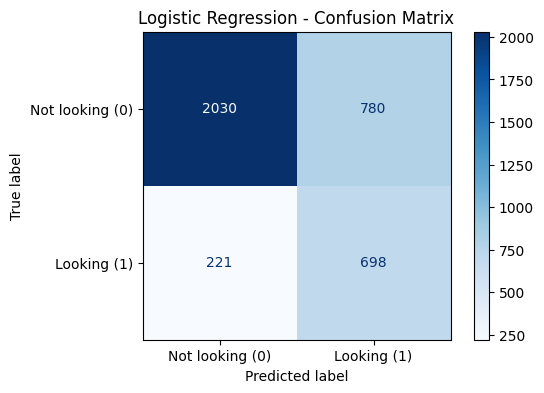

In [6]:
# Model 1: confusion matrix heatmap
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_estimator(
    best_logreg, X_test, y_test, cmap="Blues", ax=ax,
    display_labels=["Not looking (0)", "Looking (1)"],
)
plt.title("Logistic Regression - Confusion Matrix")
plt.grid(False)
plt.show()

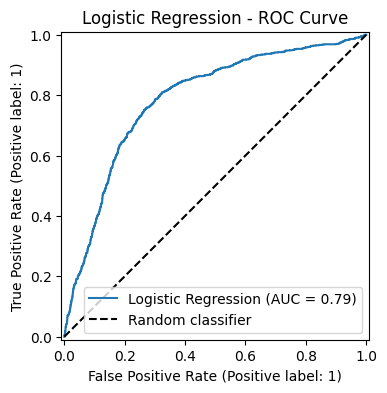

In [7]:
# Model 1: ROC curve
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 4))
RocCurveDisplay.from_estimator(best_logreg, X_test, y_test, ax=ax, name="Logistic Regression")
ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.title("Logistic Regression - ROC Curve")
plt.legend()
plt.show()

**Interpretation.** The ROC curve sits well above the random-baseline diagonal, so the model separates the two classes far better than chance across thresholds; the AUC summarises this as one number. For deployment the operating threshold can be moved along this curve — lowering it raises recall (catch more leavers) at the cost of more false positives — a dial HR can set according to how aggressively they want to intervene.

Top drivers of job-change (by |coefficient|):


,coefficient,odds_ratio
education_unknown,-1.587,0.205
major_discipline_No Major,-1.178,0.308
company_info_missing,1.165,3.207
city_development_index,-0.738,0.478
major_discipline_Unknown,0.568,1.765
company_size_unknown,0.419,1.520
major_discipline_Other,-0.338,0.713
company_type_Other,0.338,1.402
gender_Other,0.300,1.350
company_type_Funded Startup,-0.254,0.776



Features removed by L1 (coefficient = 0): 2 of 32


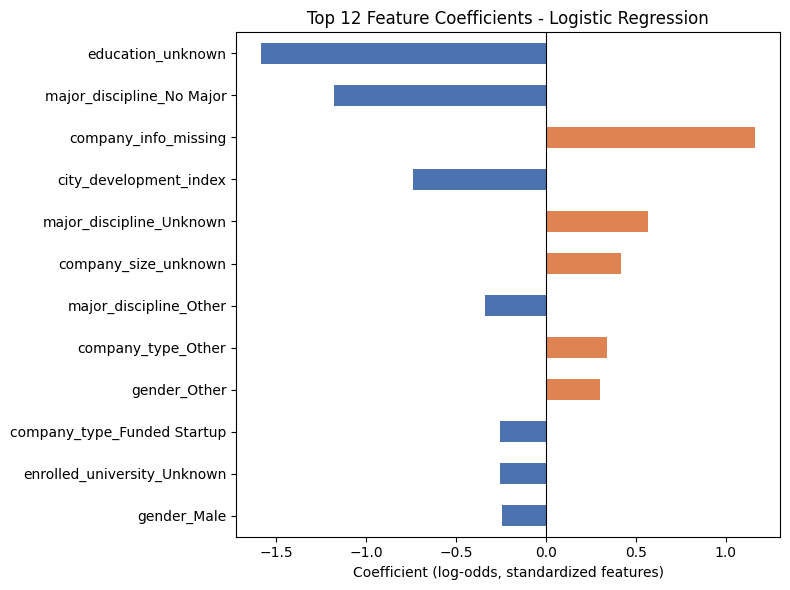

In [8]:
# Model 1: feature importance via coefficients / odds ratios
# For a linear model the coefficient magnitude (on standardized inputs) is the
# importance, and its sign is the direction. exp(coef) turns it into an odds ratio.
coef = pd.Series(best_logreg.coef_[0], index=X_train.columns)
coef_sorted = coef.reindex(coef.abs().sort_values(ascending=False).index)
odds_ratios = np.exp(coef)

# Table of the strongest drivers.
drivers = pd.DataFrame({
    "coefficient": coef_sorted,
    "odds_ratio": odds_ratios.reindex(coef_sorted.index),
}).round(3)
print("Top drivers of job-change (by |coefficient|):")
display(drivers.head(12))
print(f"\nFeatures removed by L1 (coefficient = 0): {int((coef == 0).sum())} of {len(coef)}")

# Horizontal bar chart of the top 12 (orange = raises job-change odds, blue = lowers).
top = coef_sorted.head(12)[::-1]
colors = ["#DD8452" if c > 0 else "#4C72B0" for c in top.values]
plt.figure(figsize=(8, 6))
top.plot(kind="barh", color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Top 12 Feature Coefficients - Logistic Regression")
plt.xlabel("Coefficient (log-odds, standardized features)")
plt.tight_layout()
plt.show()

**Interpretation.** For a linear model the “importance” of a feature is its coefficient: on standardized inputs a larger magnitude means a stronger effect on the log-odds of looking for a change, and the sign gives the direction. Converting to an odds ratio (exp(coef)) makes it executive-friendly. The strongest factor that raises job-change risk is `company_info_missing` (coef +1.17, odds ratio ≈ 3.2) — candidates with no current-company information have about three times the odds of looking for a change, matching the EDA (~42% vs ~18%). The strongest continuous protective factor is `city_development_index` (coef −0.74, odds ratio ≈ 0.48): candidates in more developed cities are roughly half as likely to leave. Several one-hot flags also lower the odds (`education_unknown`, `major_discipline_No Major`). All directions agree with our EDA, which is a good consistency check. With L1 at the chosen C=10 only 2 of 32 features were dropped, so the model keeps almost all features but the story is dominated by a few clear drivers.

In [9]:
# Model 1: error analysis
from sklearn.metrics import classification_report

y_pred_lr = best_logreg.predict(X_test)
y_prob_lr = best_logreg.predict_proba(X_test)[:, 1]

print("Classification report (test set):")
print(classification_report(y_test, y_pred_lr, target_names=["Not looking (0)", "Looking (1)"]))

# Split the test set into the four outcome groups.
res = pd.DataFrame({"y_true": y_test.values, "y_pred": y_pred_lr, "y_prob": y_prob_lr}, index=X_test.index)
FN = res[(res.y_true == 1) & (res.y_pred == 0)]   # missed leavers (costly)
FP = res[(res.y_true == 0) & (res.y_pred == 1)]   # false alarms
TP = res[(res.y_true == 1) & (res.y_pred == 1)]
print(f"False negatives (missed leavers): {len(FN)}   |   False positives (false alarms): {len(FP)}")

# Compare the model's mean predicted probability: FNs sit just under the 0.5 line.
print(f"\nMean predicted prob  ->  missed leavers (FN): {FN.y_prob.mean():.3f}   caught leavers (TP): {TP.y_prob.mean():.3f}")

# Where do the missed leavers differ from the caught ones? Compare a few key
# (standardized) features; a value near 0 means "about average".
for col in ["city_development_index", "experience", "company_info_missing"]:
    if col in X_test.columns:
        print(f"  mean {col:<24} FN={X_test.loc[FN.index, col].mean():+.2f}  TP={X_test.loc[TP.index, col].mean():+.2f}")

Classification report (test set):
                 precision    recall  f1-score   support

Not looking (0)       0.90      0.72      0.80      2810
    Looking (1)       0.47      0.76      0.58       919

       accuracy                           0.73      3729
      macro avg       0.69      0.74      0.69      3729
   weighted avg       0.80      0.73      0.75      3729

False negatives (missed leavers): 221   |   False positives (false alarms): 780

Mean predicted prob  ->  missed leavers (FN): 0.319   caught leavers (TP): 0.721
  mean city_development_index   FN=+0.48  TP=-0.92
  mean experience               FN=+0.20  TP=-0.42
  mean company_info_missing     FN=+0.19  TP=+0.58


**Interpretation.** The model makes far more false alarms (780 false positives) than misses (221 false negatives) — the deliberate effect of `class_weight="balanced"`, and the right trade-off for retention, where a false alarm only costs a check-in but a miss costs a departure. The missed leavers are telling: their mean predicted probability is just 0.32 (well below the 0.5 threshold), and on the strongest features they look safe — they sit in more-developed cities (mean standardized `city_development_index` +0.48 vs −0.92 for correctly caught leavers), have more experience (+0.20 vs −0.42), and less often have missing company info (+0.19 vs +0.58). Their flight-risk comes from a combination of moderate factors rather than one strong signal, and because Logistic Regression is linear it cannot capture such interactions — exactly where the non-linear XGBoost model may do better.

In [10]:
# Model 1: save artifacts for the shared comparison
import os, joblib
os.makedirs("Supervised_Learning/models", exist_ok=True)
os.makedirs("Supervised_Learning/evaluation_results", exist_ok=True)

# Fitted model (so Fatimah can reuse it without re-training).
joblib.dump(best_logreg, "Supervised_Learning/models/model1_logistic_regression.joblib")

# Test-set predictions + probabilities (so Fatimah can build the combined
# metrics table and overlay both ROC curves in Section 4.3).
pd.DataFrame(
    {"y_true": y_test.values, "y_pred": y_pred_lr, "y_prob": y_prob_lr},
    index=X_test.index,
).to_csv("Supervised_Learning/evaluation_results/model1_logreg_test_predictions.csv")

print("Saved: model1_logistic_regression.joblib and model1_logreg_test_predictions.csv")

Saved: model1_logistic_regression.joblib and model1_logreg_test_predictions.csv


### 4.2 Model 2 (Ghala)

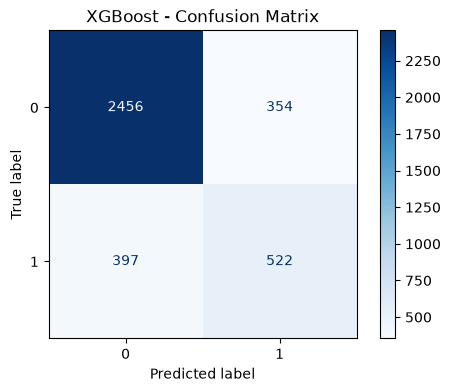

In [6]:
# 1. Confusion Matrix Heatmap
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_estimator(best_xgb_model, X_test, y_test, cmap="Blues", ax=ax)
plt.title("XGBoost - Confusion Matrix")
plt.grid(False)
plt.show()

The confusion matrix shows the distribution of true positives, true negatives, false positives, and false negatives. Given that the dataset is imbalanced (~25% positive rate), our primary focus is minimizing false negatives to ensure potential employee attrition is identified reliably.

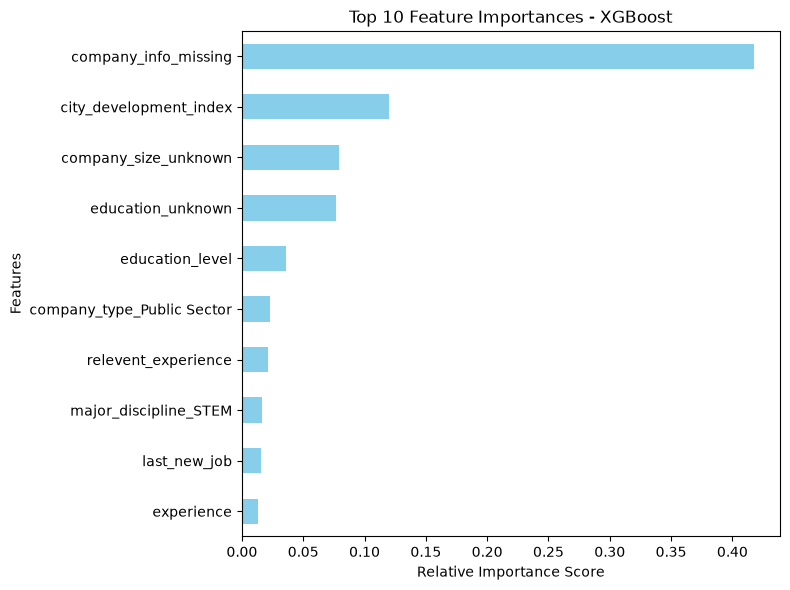

In [7]:
# 2. Feature Importance Plot
feature_importances = pd.Series(best_xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 6))
feature_importances.tail(10).plot(kind='barh', color='skyblue')
plt.title("Top 10 Feature Importances - XGBoost")
plt.xlabel("Relative Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

The feature importance chart displays the top factors driving the model's predictions. Features with higher relative importance scores have the strongest influence on determining whether an employee is likely to look for a job change.

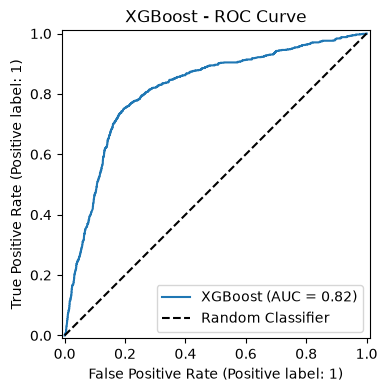

In [8]:
# 3. ROC Curve Plot
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 4))
RocCurveDisplay.from_estimator(best_xgb_model, X_test, y_test, ax=ax, name="XGBoost")
plt.title("XGBoost - ROC Curve")
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")
plt.legend()
plt.show()

The Receiver Operating Characteristic (ROC) curve evaluates the trade-off between the True Positive Rate and False Positive Rate across various threshold levels. An Area Under the Curve (ROC-AUC) score significantly above 0.50 demonstrates strong discrimination capability between positive and negative classes.

In [ ]:
# Model 2: test-set metrics + 5-fold cross-validation
from sklearn.base import clone

# Side-by-side baseline vs tuned on the test set.
metrics_table_xgb = pd.DataFrame([xgb_default_results, tuned_xgb_results]).set_index("Model")
print("Test-set metrics:")
display(metrics_table_xgb.round(4))

# 5-fold stratified cross-validation of the TUNED model on the training set,
# reported for every required metric (mean +/- std across folds).
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_results_xgb = cross_validate(clone(best_xgb_model), X_train, y_train, cv=cv, scoring=scoring)
cv_summary_xgb = pd.DataFrame(
    {m: [cv_results_xgb[f"test_{m}"].mean(), cv_results_xgb[f"test_{m}"].std()] for m in scoring},
    index=["mean", "std"],
).T.round(4)
print("\n5-fold CV (tuned XGBoost, training set):")
display(cv_summary_xgb)

Test-set metrics:


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
XGBoost (Baseline),0.7922,0.5878,0.5245,0.5543,0.8052
XGBoost (Tuned),0.7986,0.5959,0.5680,0.5816,0.8159



5-fold CV (tuned XGBoost, training set):


,mean,std
accuracy,0.7978,0.0084
precision,0.5935,0.0184
recall,0.5710,0.0226
f1,0.5818,0.0182
roc_auc,0.8003,0.0165


**Interpretation.** On the held-out test set the tuned XGBoost reaches **ROC-AUC ≈ 81.59%** with **accuracy ≈ 79.86%**, precision ≈ 59.59% and **recall ≈ 56.80%** on the minority "looking" class (F1 ≈ 58.16%). Tuning improved the baseline on every metric (F1 55.43% → 58.16%, ROC-AUC 80.52% → 81.59%). The 5-fold CV means (ROC-AUC ≈ 80.03%, recall ≈ 57.10%, F1 ≈ 58.18%) are close to the test-set numbers and the standard deviations are small (at most 0.023), so the model is **stable and not over-fitting** one particular split. XGBoost was trained without class weights, so at the default 0.5 threshold it is more careful than Logistic Regression: its precision is higher but its recall is lower. Section 5 shows that lowering the threshold recovers much of this recall.

In [ ]:
# Model 2: error analysis
from sklearn.metrics import classification_report

y_pred_xgb = best_xgb_model.predict(X_test)
y_prob_xgb = best_xgb_model.predict_proba(X_test)[:, 1]

print("Classification report (test set):")
print(classification_report(y_test, y_pred_xgb, target_names=["Not looking (0)", "Looking (1)"]))

# Split the test set into the outcome groups.
res_xgb = pd.DataFrame({"y_true": y_test.values, "y_pred": y_pred_xgb, "y_prob": y_prob_xgb}, index=X_test.index)
FN_x = res_xgb[(res_xgb.y_true == 1) & (res_xgb.y_pred == 0)]   # missed leavers (costly)
FP_x = res_xgb[(res_xgb.y_true == 0) & (res_xgb.y_pred == 1)]   # false alarms
TP_x = res_xgb[(res_xgb.y_true == 1) & (res_xgb.y_pred == 1)]
print(f"False negatives (missed leavers): {len(FN_x)}   |   False positives (false alarms): {len(FP_x)}")

# Mean predicted probability: missed leavers vs caught leavers.
print(f"\nMean predicted prob  ->  missed leavers (FN): {FN_x.y_prob.mean():.3f}   caught leavers (TP): {TP_x.y_prob.mean():.3f}")

# Where do the missed leavers differ from the caught ones? (standardized features, 0 = average)
for col in ["city_development_index", "experience", "company_info_missing"]:
    if col in X_test.columns:
        print(f"  mean {col:<24} FN={X_test.loc[FN_x.index, col].mean():+.2f}  TP={X_test.loc[TP_x.index, col].mean():+.2f}")

Classification report (test set):
                 precision    recall  f1-score   support

Not looking (0)       0.86      0.87      0.87      2810
    Looking (1)       0.60      0.57      0.58       919

       accuracy                           0.80      3729
      macro avg       0.73      0.72      0.72      3729
   weighted avg       0.80      0.80      0.80      3729

False negatives (missed leavers): 397   |   False positives (false alarms): 354

Mean predicted prob  ->  missed leavers (FN): 0.244   caught leavers (TP): 0.598
  mean city_development_index   FN=+0.04  TP=-1.06
  mean experience               FN=+0.02  TP=-0.50
  mean company_info_missing     FN=+0.43  TP=+0.53


**Interpretation.** At the 0.5 threshold XGBoost makes more misses (397 false negatives) than false alarms (354 false positives), the opposite of Logistic Regression. For HR retention, where a missed leaver costs more than a false alarm, these 397 misses are its main weakness. The missed leavers have a mean predicted probability of only 0.24, well below the 0.5 threshold, and on the strongest features they look average or safe: their standardized `city_development_index` is +0.04 versus −1.06 for correctly caught leavers, and their `experience` is +0.02 versus −0.50. In other words, caught leavers tend to live in less developed cities and have less experience, while the missed ones do not stand out on these features, so the model has little signal for them. `company_info_missing` is similar for both groups (+0.43 vs +0.53), so missing company information alone does not explain the misses. Because the model separates the classes well (ROC-AUC 0.816), many of these misses can be recovered by lowering the decision threshold, which Section 5 evaluates.

### 4.3 Side-by-Side Metrics and ROC Curves (Fatimah)
*Both models on the same test set and the same 5-fold CV.*

In [ ]:
# Extra imports and output folders for the comparison (Sections 4.3 - 5)
import warnings
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

RESULTS_DIR = "Supervised_Learning/evaluation_results"
PLOTS_DIR = "Supervised_Learning/plots"

# The two tuned models trained earlier in this notebook
LR_NAME = "Logistic Regression"
XGB_NAME = "XGBoost"
models = {LR_NAME: best_logreg, XGB_NAME: best_xgb_model}

# test predictions and probabilities
preds = {name: m.predict(X_test) for name, m in models.items()}
probs = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}

#### Test-set metrics

In [4]:
# test metrics and confusion matrix counts for both models (threshold 0.5)
rows = []
for name, m in models.items():
    row = evaluate_model(name, m, X_test, y_test)
    tn, fp, fn, tp = confusion_matrix(y_test, preds[name]).ravel()
    row.update({"TN": tn, "FP": fp, "FN": fn, "TP": tp})
    rows.append(row)
metrics_table = pd.DataFrame(rows).set_index("Model")
metrics_table.to_csv(f"{RESULTS_DIR}/metrics_comparison.csv")

metric_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
display(metrics_table[metric_cols].round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.7316,0.4723,0.7595,0.5824,0.7865
XGBoost,0.7986,0.5959,0.5680,0.5816,0.8159


**Interpretation.** The two models have almost the same F1 (0.582 and 0.582), but for different reasons. Logistic Regression has high recall (0.76) and low precision (0.47). It finds most of the candidates who are looking for a job, but it also gives many false alarms. XGBoost has higher precision (0.60) and accuracy (0.80) but lower recall (0.57). It is right more often when it flags someone, but it misses more leavers. XGBoost also has the higher ROC-AUC (0.816 vs 0.786), so it is better at ranking candidates by risk. Accuracy alone is not enough here, because a model that always says "not looking" already gets about 75%.

#### 5-fold cross-validation (mean and std)

In [5]:
# 5-fold CV on the training set for both models
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_rows = []
for name, m in models.items():
    scores = cross_validate(clone(m), X_train, y_train, cv=cv, scoring=scoring)
    for s in scoring:
        cv_rows.append({"Model": name, "Metric": s,
                        "mean": scores[f"test_{s}"].mean(),
                        "std": scores[f"test_{s}"].std()})

cv_long = pd.DataFrame(cv_rows)
cv_long.to_csv(f"{RESULTS_DIR}/cv_results.csv", index=False)

# show it as mean +/- std
cv_long["mean +/- std"] = cv_long["mean"].map("{:.4f}".format) + " +/- " + cv_long["std"].map("{:.4f}".format)
cv_table = cv_long.pivot(index="Metric", columns="Model", values="mean +/- std").loc[scoring]
display(cv_table)

Model,Logistic Regression,XGBoost
Metric,,
accuracy,0.7308 +/- 0.0115,0.7978 +/- 0.0084
precision,0.4706 +/- 0.0149,0.5935 +/- 0.0184
recall,0.7375 +/- 0.0290,0.5710 +/- 0.0226
f1,0.5745 +/- 0.0185,0.5818 +/- 0.0182
roc_auc,0.7780 +/- 0.0168,0.8003 +/- 0.0165


**Interpretation.** The CV means are close to the test numbers, and the standard deviations are small (about 0.01 to 0.03). So both models are stable, and the test result is not just a lucky split. The pattern is the same as on the test set. Logistic Regression has higher recall (0.74 vs 0.57). XGBoost has higher precision (0.59 vs 0.47) and accuracy. F1 is almost equal (0.575 vs 0.582). XGBoost has the higher mean ROC-AUC (0.800 vs 0.778). The difference is not big, but it is in the same direction as on the test set.

#### Confusion matrix heatmaps

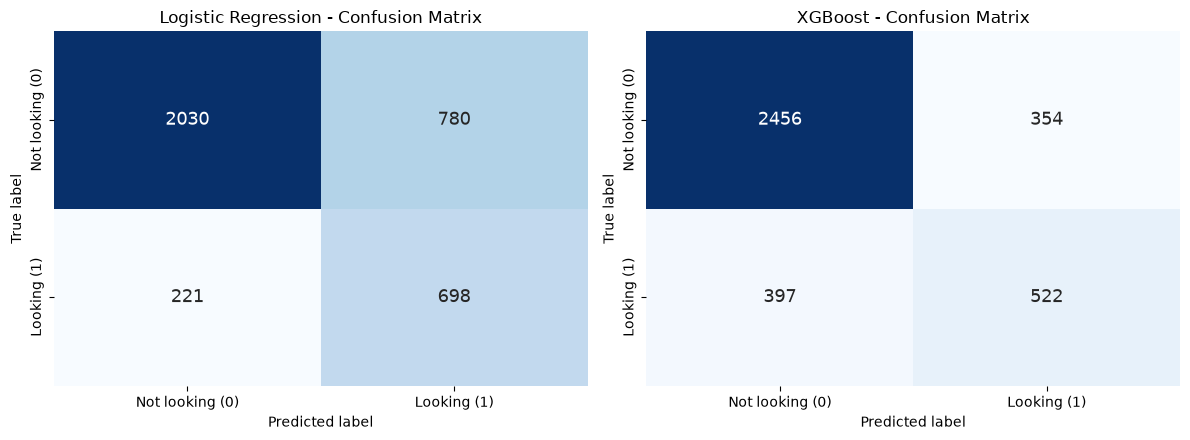

In [6]:
# confusion matrices side by side
labels = ["Not looking (0)", "Looking (1)"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels, annot_kws={"size": 13})
    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/confusion_matrices.png", dpi=150)
plt.show()

**Interpretation.** The test set has 919 candidates who are really looking for a job. Logistic Regression misses 221 of them and XGBoost misses 397. On the other side, Logistic Regression wrongly flags 780 candidates who are not looking, and XGBoost wrongly flags only 354. So at the 0.5 threshold, Logistic Regression catches more leavers but gives more false alarms, and XGBoost gives fewer false alarms but misses more leavers. For HR, a missed leaver usually costs more than a false alarm. So the 397 misses are the main weakness of XGBoost at this threshold.

#### ROC curves on one plot

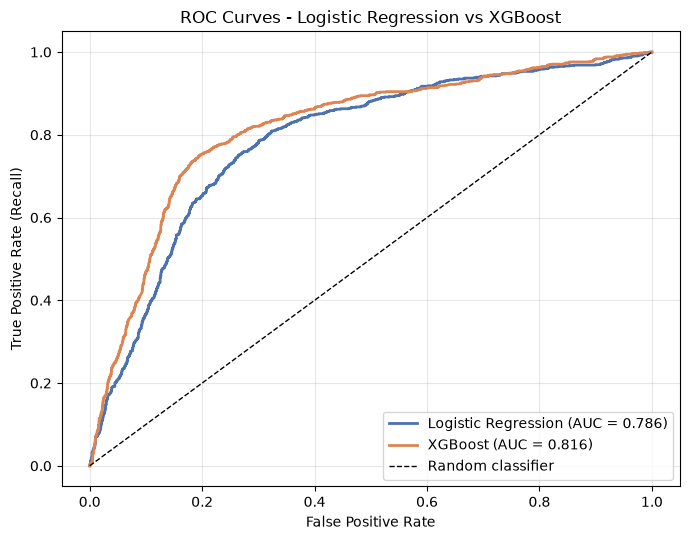

In [7]:
# both ROC curves on the same plot
colors = {LR_NAME: "#4C72B0", XGB_NAME: "#DD8452"}
plt.figure(figsize=(7, 5.5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    auc = roc_auc_score(y_test, probs[name])
    plt.plot(fpr, tpr, color=colors[name], lw=2, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves - Logistic Regression vs XGBoost")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/roc_curves.png", dpi=150)
plt.show()

**Interpretation.** Both curves are far above the random line, so both models are much better than guessing. The XGBoost curve is above the Logistic Regression curve on the left side of the plot, up to a false positive rate of about 0.5. After that the two curves are almost the same (AUC 0.816 vs 0.786). The left side is the part we care about, because the system should not give too many false alarms. There, XGBoost catches more leavers for the same rate of false alarms. This also shows that the low recall of XGBoost in the table comes from the 0.5 threshold. It does not mean the model is worse at finding leavers.

## 5. Model Comparison & Analysis

### 5.1 Which model performed best, and why?

At the 0.5 threshold the two models have the same F1, so the answer depends on the metric:

- **Ranking (ROC-AUC):** XGBoost is better on the test set (0.816 vs 0.786) and in cross-validation (0.800 vs 0.778). This metric does not depend on the threshold.
- **Recall at 0.5:** Logistic Regression is better (0.76 vs 0.57).

The recall difference comes mostly from how the models were trained. Logistic Regression used `class_weight="balanced"`, so it predicts the minority class more often. XGBoost was trained without class weights, so at 0.5 it flags fewer candidates. To compare them fairly, I choose a threshold for each model using only the training data (out-of-fold predictions from the same 5-fold CV). Then I apply it one time to the test set.

In [8]:
# pick the threshold with the best F1 on the training folds (test set not used)
thresholds = np.arange(0.10, 0.91, 0.01)
best_thresholds = {}
for name, m in models.items():
    oof_prob = cross_val_predict(clone(m), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    f1_values = [f1_score(y_train, oof_prob >= t) for t in thresholds]
    best_thresholds[name] = round(float(thresholds[int(np.argmax(f1_values))]), 2)
print("Threshold with the best CV F1:", best_thresholds)

# test metrics at a given threshold
def metrics_at(name, t):
    pred = (probs[name] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Model": name, "Threshold": t,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "Missed leavers (FN)": fn, "False alarms (FP)": fp}

thr_rows = []
for name in models:
    thr_rows.append(metrics_at(name, 0.5))
    thr_rows.append(metrics_at(name, best_thresholds[name]))
threshold_table = pd.DataFrame(thr_rows).set_index(["Model", "Threshold"])
display(threshold_table.round(4))

Threshold with the best CV F1: {'Logistic Regression': 0.55, 'XGBoost': 0.32}


Accuracy  Precision  Recall      F1  \
Model               Threshold                                        
Logistic Regression 0.50         0.7316     0.4723  0.7595  0.5824   
                    0.55         0.7490     0.4935  0.7073  0.5814   
XGBoost             0.50         0.7986     0.5959  0.5680  0.5816   
                    0.32         0.7999     0.5755  0.7171  0.6386   

                               Missed leavers (FN)  False alarms (FP)  
Model               Threshold                                          
Logistic Regression 0.50                       221                780  
                    0.55                       269                667  
XGBoost             0.50                       397                354  
                    0.32                       260                486

**Interpretation.** For Logistic Regression the best CV threshold is 0.55. This is close to 0.5 and changes very little (F1 stays at 0.58). For XGBoost the best CV threshold is 0.32, and it changes a lot. Recall goes from 0.57 to 0.72 and F1 goes from 0.58 to 0.64, while accuracy stays at 0.80. Compared with Logistic Regression at 0.5, XGBoost at 0.32 catches a few less leavers (659 vs 698 out of 919) but gives far fewer false alarms (486 vs 780).

So **XGBoost performed best**, but only when its threshold is lowered. The reason is that it ranks candidates better (higher ROC-AUC). It is a tree model, so it can learn non-linear effects and combinations of features. A linear model cannot do that. Logistic Regression looked equal at 0.5 only because class weighting had already moved it to a high-recall point.

### 5.2 Misclassification patterns and challenging categories

In [9]:
# compare the mistakes of the two models on the test set
y_true = y_test.values
lr_wrong = preds[LR_NAME] != y_true
xgb_wrong = preds[XGB_NAME] != y_true

cases = {
    "Both models wrong": lr_wrong & xgb_wrong,
    "Only Logistic Regression wrong": lr_wrong & ~xgb_wrong,
    "Only XGBoost wrong": ~lr_wrong & xgb_wrong,
}
overlap = pd.DataFrame({
    "All errors": [mask.sum() for mask in cases.values()],
    "Missed leavers (FN)": [(mask & (y_true == 1)).sum() for mask in cases.values()],
    "False alarms (FP)": [(mask & (y_true == 0)).sum() for mask in cases.values()],
}, index=list(cases.keys()))
display(overlap)

,All errors,Missed leavers (FN),False alarms (FP)
Both models wrong,548,206,342
Only Logistic Regression wrong,453,15,438
Only XGBoost wrong,203,191,12


**Interpretation.** Both models are wrong on the same 548 test candidates. So a big part of the errors are hard cases, not a problem of one algorithm. 206 leavers are missed by both models. The errors that only one model makes follow the trade-off from Section 4.3. The errors of only Logistic Regression are almost all false alarms (438 of 453). The errors of only XGBoost are almost all missed leavers (191 of 203). Almost every leaver that Logistic Regression misses is also missed by XGBoost (206 of 221).

In [10]:
# error rates in each group of candidates (threshold 0.5)
# numeric features are standardized, so 0 is the average
groups = {
    "Company info": np.where(X_test["company_info_missing"] == 1, "missing", "known"),
    "City development": np.where(X_test["city_development_index"] >= 0, "above average", "below average"),
    "Experience": np.where(X_test["experience"] >= 0, "above average", "below average"),
    "Relevant experience": np.where(X_test["relevent_experience"] == 1, "yes", "no"),
}

group_rows = []
for feature, values in groups.items():
    for value in sorted(set(values)):
        mask = values == value
        pos = mask & (y_true == 1)
        neg = mask & (y_true == 0)
        group_rows.append({
            "Feature": feature, "Group": value, "Candidates": mask.sum(),
            "Looking rate": y_true[mask].mean(),
            "LR miss rate": (preds[LR_NAME][pos] == 0).mean(),
            "XGB miss rate": (preds[XGB_NAME][pos] == 0).mean(),
            "LR false alarm rate": (preds[LR_NAME][neg] == 1).mean(),
            "XGB false alarm rate": (preds[XGB_NAME][neg] == 1).mean(),
        })
group_table = pd.DataFrame(group_rows).set_index(["Feature", "Group"])
display(group_table.round(3))

Candidates  Looking rate  LR miss rate  \
Feature             Group                                                   
Company info        known                2667         0.178         0.378   
                    missing              1062         0.419         0.094   
City development    above average        2462         0.156         0.491   
                    below average        1267         0.421         0.060   
Experience          above average        1551         0.171         0.404   
                    below average        2178         0.300         0.174   
Relevant experience no                   1073         0.332         0.177   
                    yes                  2656         0.212         0.281   

                                   XGB miss rate  LR false alarm rate  \
Feature             Group                                               
Company info        known                  0.481                0.155   
                    missing                0.380                0.713   
City development    above average          0.649                0.119   
                    below average          0.275                0.726   
Experience          above average          0.634                0.172   
                    below average          0.350                0.367   
Relevant experience no                     0.421                0.434   
                    yes                    0.439                0.224   

                                   XGB false alarm rate  
Feature             Group                                
Company info        known                         0.079  
                    missing                       0.292  
City development    above average                 0.039  
                    below average                 0.372  
Experience          above average                 0.052  
                    below average                 0.188  
Relevant experience no                            0.185  
                    yes                           0.106

**Interpretation.** The miss rate is the share of real leavers in a group that the model did not flag. The false alarm rate is the share of candidates who are not looking but were flagged.

The hardest candidates for both models are the leavers who look "safe". In cities with above-average development, Logistic Regression misses 49% of the real leavers and XGBoost misses 65%. For candidates with above-average experience, the miss rates are 40% and 63%. Only about 16% to 17% of these groups are looking for a job, so both models learn to say "not looking" for them.

The high-risk groups have the opposite problem. These are candidates with below-average city development or missing company information, where about 42% are looking. Here Logistic Regression flags almost everyone, so its false alarm rate is very high (73% and 71%). XGBoost is more careful in these groups (37% and 29% false alarms), but it misses more of the leavers (28% and 38%).

At the 0.5 threshold XGBoost misses a larger share of leavers than Logistic Regression in every group. The biggest gap is for candidates with missing company information (9% vs 38%). These are high-risk candidates that XGBoost scores a little under 0.5. This is one more reason to lower its threshold.

### 5.3 Trade-offs: accuracy vs interpretability vs computational cost

| | Logistic Regression | XGBoost |
|---|---|---|
| **Predictive performance** | ROC-AUC 0.786, F1 0.58. Good recall at 0.5 because of class weighting. | ROC-AUC 0.816. F1 is 0.58 at 0.5 and 0.64 at the tuned threshold. Better ranking. |
| **Interpretability** | High. Each feature has one coefficient. It is easy to turn it into an odds ratio ("3 times the odds") and explain it to HR leaders. | Lower. We cannot read 50 trees directly. Feature importance shows what matters but not the direction, so extra tools such as SHAP are needed. |
| **Computational cost** | Low. Small grid search (50 fits). | Low to train one time, but it has more parameters to tune (270 fits), and the threshold also needs tuning. |

Computational cost is not a problem for this dataset (about 15,000 training rows and 32 features). Both models train in about a second. The real difference is in tuning: XGBoost needed 270 grid search fits and Logistic Regression needed 50.

The main trade-off is between a bit more predictive power (XGBoost) and a much simpler explanation (Logistic Regression). The gain from XGBoost is real but not large: about 0.02 to 0.03 in ROC-AUC, and 0.06 in F1 after threshold tuning. `company_info_missing` and `city_development_index` are among the strongest drivers in both models. So the explanation we give to leadership does not conflict with the model that makes the predictions.

## 6. Conclusion: Best Model Selection & Reasoning

**Selected model for the final system: XGBoost (Model 2, with the tuned parameters), used with a decision threshold of 0.32 instead of 0.5.**

Reasons:

1. **It ranks candidates better.** XGBoost has the higher ROC-AUC on the test set (0.816 vs 0.786) and in cross-validation (mean 0.800 vs 0.778). The system should rank candidates by job-change risk, so this is the most important metric. It also does not depend on the threshold.
2. **It has a better balance after the threshold is fixed.** With the threshold chosen on the training folds (0.32), XGBoost gets recall 0.72, precision 0.58 and F1 0.64 on the test set. Logistic Regression gets recall 0.76, precision 0.47 and F1 0.58. XGBoost finds almost as many leavers with about 300 fewer false alarms. So HR spends less time on candidates who were not going to leave.
3. **It is stable.** The CV standard deviations are small and the test numbers agree with the CV means, so there is no sign of overfitting.
4. **Cost is not a problem** at this data size.

Conditions and limits of this choice:

- **The threshold matters.** At 0.5, XGBoost misses 397 of 919 leavers (recall 0.57). This is too many for a retention tool. If the model is used at 0.5, Logistic Regression is the safer choice. HR can also lower the threshold more if they want to catch more leavers and accept more false alarms.
- **Logistic Regression stays as the explanation model.** Its coefficients and odds ratios give a clear story about the key drivers for leadership. It is also a good baseline to check the XGBoost predictions.
- **The performance is moderate.** Precision is around 0.58, so about 4 of every 10 flagged candidates are not really looking. The output should be used as a risk score to help HR decide who to talk to first. It should not be an automatic decision about a person. About 200 leavers are missed by both models. They are mostly experienced candidates in developed cities, and the features we have cannot separate them well.

## 7. Next Steps for Phase 2 Integration

**Before Phase 2 starts**
- Save the final XGBoost model with `joblib` in `Supervised_Learning/models/` together with the chosen threshold. It was not saved in Phase 1, and this way Phase 2 does not need to train it again.
- Score all candidates. Store the predicted probability (risk score) and a risk level (for example low / medium / high) next to each row.

**Clustering (unsupervised learning)**
- Cluster the candidates on the same preprocessed features (for example K-Means, choosing the number of clusters with the elbow method and the silhouette score). Save the result as `Dataset/clustered_data.csv`.
- Combine the two outputs. For each cluster, report its size, its average risk score and its share of high-risk candidates. This gives segments such as "early-career candidates in low-development cities with no company information". Segments are easier for HR to act on than single predictions.
- Look at the clusters where the model makes most of its errors (Section 5.2), especially experienced candidates in developed cities. They may be a separate segment that needs a different approach.

**Generative AI executive briefings**
- Build structured prompt templates that receive facts from our code: the model metrics, the top drivers (Logistic Regression odds ratios and XGBoost importances) and the risk summary of each cluster.
- The language model only writes the text of the briefing (summary, key risks, recommended retention actions). All numbers come from our tables, and the prompt tells the model not to add numbers that were not given.
- Send only aggregated numbers to the language model, not single candidate records. Keep the API key out of the repository (`.env` is already in `.gitignore`).
- Include the model limits in the briefing (precision around 0.58), so executives read the score as a signal and not as a sure fact.

**Executive dashboard**
- Overview: number of candidates, share at high risk and the main model metrics.
- Risk view: the distribution of risk scores, with filters for city development, experience and company information.
- Threshold control: a slider that shows how recall, precision and the number of flagged candidates change. It starts at 0.32.
- Drivers view: the key drivers chart from Logistic Regression.
- Segments view: the clusters with their risk level and the generated briefing for each one.